# Lab 1 — Experimental Discovery of Algorithmic Complexity
### Advanced Algorithms and Complexity — Master in AI and Master in RSD

| | |
|---|---|
| **Lectures & Tutorials** | Dr. Benyamina Ahmed |
| **Labs** | Mahkouka Mohamed Fouad |
| **Duration** | 1 session |

---

**Objective:** observe how the **number of operations** and the **execution time** change as the **input size** grows.

> ℹ️ You are given **five Python programs**. For each one: run it for several values of $n$, **count the number of times the given elementary operation runs**, **measure the execution time**, **fill in the table** and **draw the requested graph**.

## Your work (for each program)

1. Run the program for several values of $n$.
2. Count how many times the elementary operation shown in the code is executed.
3. Measure the execution time (in seconds) on the lab machine.
4. Fill in the results table.
5. Draw the requested graph(s).
6. Describe what you observe as $n$ grows.
7. Conclude about the algorithm's behaviour (**without using $O(\cdot)$ notation**).

## Results table (fill in for each program)

| $n$ (input size) | Number of operations (counted) | Execution time (seconds) |
|---|---|---|
| 10 | | |
| 100 | | |
| 1,000 | | |
| … | | |

## Graphs to draw

- **Graph 1**: number of operations (y-axis) as a function of $n$ (x-axis).
- **Graph 2**: execution time (seconds, y-axis) as a function of $n$ (x-axis).
- **Base-10 logarithmic scale** on both axes.

## 💡 Important instructions

- Repeat each measurement **at least 3 times** and take the **average** time.
- Write **the name of the program tested** on your graphs.
- Do not try to find a mathematical formula. **Simply describe the shape of the curve** and what you observe.

---
# Measurement tools

**Run this cell first** (you do not need to change it). These are the tools from **Lab 0, Part 5**.

| Function | Purpose |
|---|---|
| `timer(f, *args)` | **average** time of `f(*args)` over **3 runs** |
| `show_table(sizes, operations, times)` | prints the **results table** |
| `plot(program_name, sizes, operations, times)` | draws **graphs 1 and 2** on a base-10 log scale, with the program name |

In [1]:
import time
import matplotlib.pyplot as plt


def timer(f, *args, repetitions=3):
    # Average time (in seconds) of f(*args) over 3 runs.
    total = 0.0
    for _ in range(repetitions):
        start = time.perf_counter()
        f(*args)
        total += time.perf_counter() - start
    return total / repetitions


def show_table(sizes, operations, times):
    # Prints the results table.
    print(f"{'n':>10} | {'operations (count)':>20} | {'time (s)':>10}")
    print("-" * 47)
    for n, o, t in zip(sizes, operations, times):
        print(f"{n:>10,} | {o:>20,} | {t:>10.6f}")


def plot(program_name, sizes, operations, times):
    # Graph 1: operations as a function of n. Graph 2: time as a function of n.
    # Base-10 logarithmic scale on both axes.
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.loglog(sizes, operations, "o-")
    ax1.set(title="Graph 1: number of operations", xlabel="n (input size)", ylabel="number of operations")
    ax2.loglog(sizes, times, "o-", color="tab:red")
    ax2.set(title="Graph 2: execution time", xlabel="n (input size)", ylabel="time (s)")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.3)
    fig.suptitle(program_name)
    plt.tight_layout()
    plt.show()


print("Tools ready ✅")

Tools ready ✅


---
# Program 1 — Simple traversal

```python
def traversal(n):
    counter = 0
    for i in range(n):
        counter += 1   # elementary operation
    return counter
```

**What does this program do?** It goes through $n$ elements one by one and performs the same operation at each iteration.

**Elementary operation to count:** the increment `counter += 1`.

> 📌 This first program is **fully done**: use it as the **model** for the next four.

In [2]:
def traversal(n):
    counter = 0
    for i in range(n):
        counter += 1   # elementary operation
    return counter

         n |   operations (count) |   time (s)
-----------------------------------------------
        10 |                   10 |   0.000001
       100 |                  100 |   0.000003
     1,000 |                1,000 |   0.000218
    10,000 |               10,000 |   0.000630
   100,000 |              100,000 |   0.012874
 1,000,000 |            1,000,000 |   0.262089


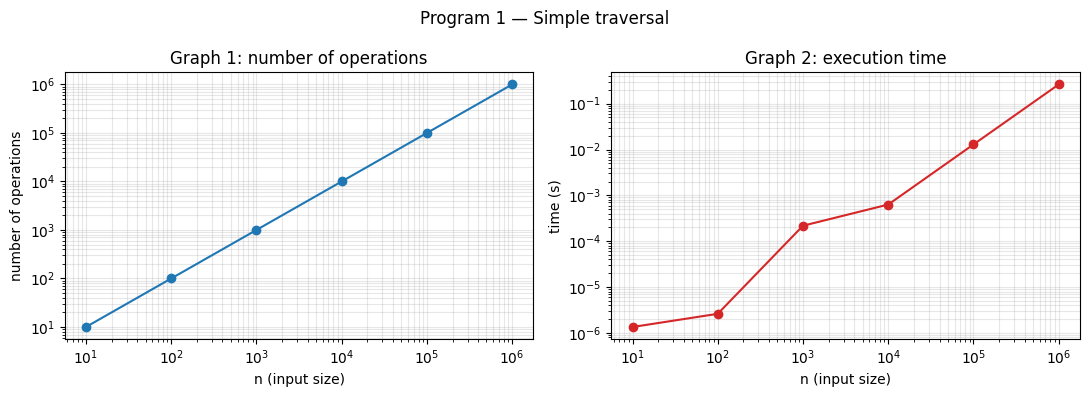

In [3]:
sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
operations, times = [], []

for n in sizes:
    operations.append(traversal(n))      # 2. count
    times.append(timer(traversal, n))    # 3. measure (average of 3)

show_table(sizes, operations, times)                              # 4. table
plot("Program 1 — Simple traversal", sizes, operations, times)    # 5. graphs

> ✍️ **What I observe as n grows:** when $n$ is multiplied by 10, the number of operations is multiplied by 10, and so is the time (roughly). Both curves are straight lines.
>
> ✍️ **Conclusion about the algorithm's behaviour:** the work grows at the same rate as $n$: twice as much data means twice as much work.

*(sample answer: do the same for the next programs)*

---
# Program 2 — Sequential search

```python
def sequential_search(T, x):
    counter = 0
    for e in T:
        counter += 1   # comparison
        if e == x:
            return counter
    return counter
```

**What does this program do?** It searches for the value `x` in the array `T` by going through the elements from left to right.

**Elementary operation to count:** `counter += 1` (the comparison).

Here the result depends on **where `x` is**. We use `T = [1, 2, 3, …, n]` and test **4 situations**:

| Situation | Value searched |
|---|---|
| Start (position 1) | `x = T[0]` |
| Middle (≈ n/2) | `x = T[n // 2]` |
| End (position n) | `x = T[n - 1]` |
| Absent | `x = 0` (not in `T`) |

In [4]:
def sequential_search(T, x):
    counter = 0
    for e in T:
        counter += 1   # comparison
        if e == x:
            return counter
    return counter

### ✍️ To program
Each situation has a list of operations and a list of times ready. Complete the loop, then plot the graphs of the 4 situations.

In [5]:
sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
ops_start, ops_middle, ops_end, ops_absent = [], [], [], []
t_start, t_middle, t_end, t_absent = [], [], [], []

for n in sizes:
    T = list(range(1, n + 1))       # T = [1, 2, ..., n]
    # Start: x = T[0]
    ops_start.append(sequential_search(T, T[0]))
    t_start.append(timer(sequential_search, T, T[0]))
    # Middle: x = T[n // 2]
    ops_middle.append(sequential_search(T, T[n // 2]))
    t_middle.append(timer(sequential_search, T, T[n // 2]))
    # End: x = T[n - 1]
    ops_end.append(sequential_search(T, T[n - 1]))
    t_end.append(timer(sequential_search, T, T[n - 1]))
    # Absent: x = 0
    ops_absent.append(sequential_search(T, 0))
    t_absent.append(timer(sequential_search, T, 0))

print("Start"); show_table(sizes, ops_start, t_start)
print("\nMiddle"); show_table(sizes, ops_middle, t_middle)
print("\nEnd"); show_table(sizes, ops_end, t_end)
print("\nAbsent"); show_table(sizes, ops_absent, t_absent)

Start
         n |   operations (count) |   time (s)
-----------------------------------------------
        10 |                    1 |   0.000001
       100 |                    1 |   0.000000
     1,000 |                    1 |   0.000000
    10,000 |                    1 |   0.000000
   100,000 |                    1 |   0.000001
 1,000,000 |                    1 |   0.000001

Middle
         n |   operations (count) |   time (s)
-----------------------------------------------
        10 |                    6 |   0.000001
       100 |                   51 |   0.000002
     1,000 |                  501 |   0.000020
    10,000 |                5,001 |   0.000998
   100,000 |               50,001 |   0.002902
 1,000,000 |              500,001 |   0.033528

End
         n |   operations (count) |   time (s)
-----------------------------------------------
        10 |                   10 |   0.000001
       100 |                  100 |   0.000003
     1,000 |                1,000 |   

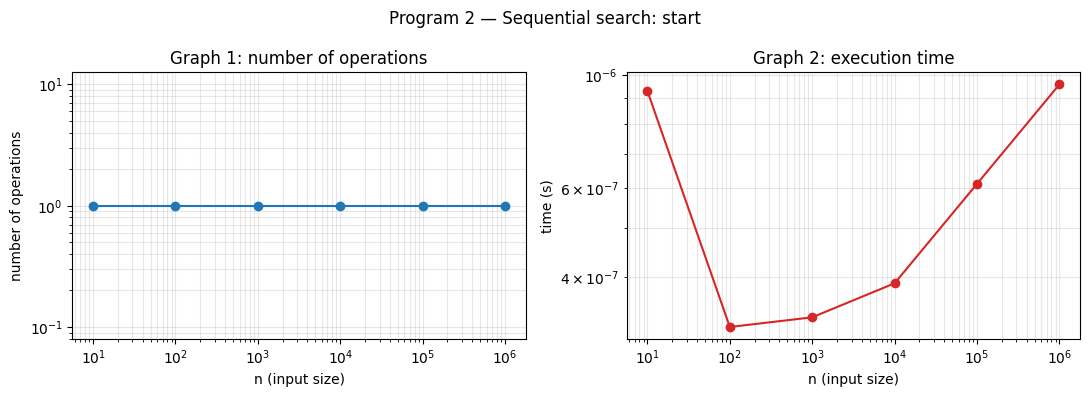

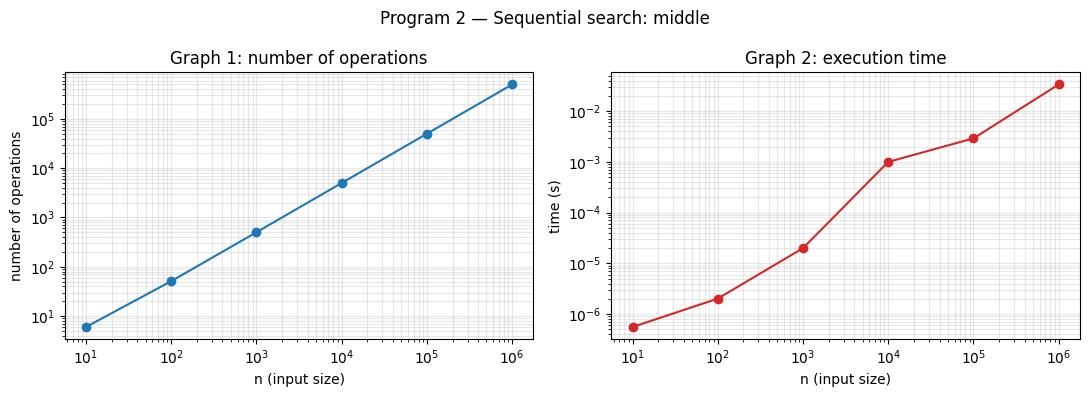

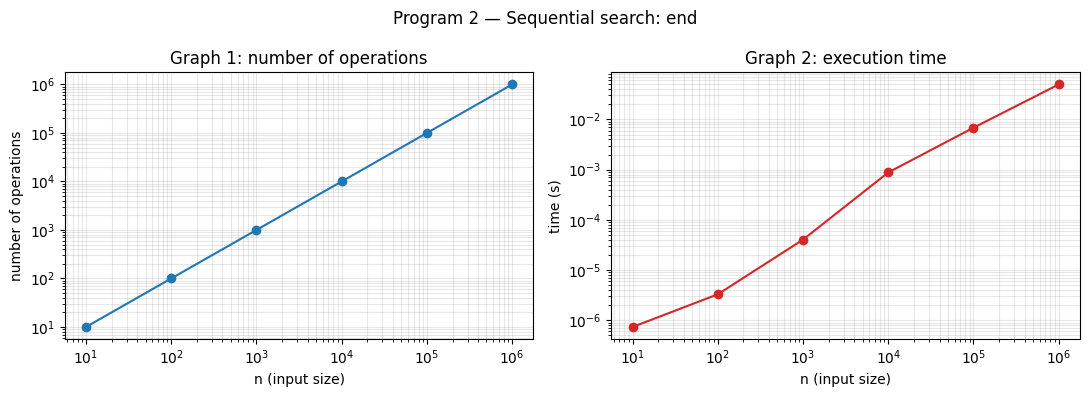

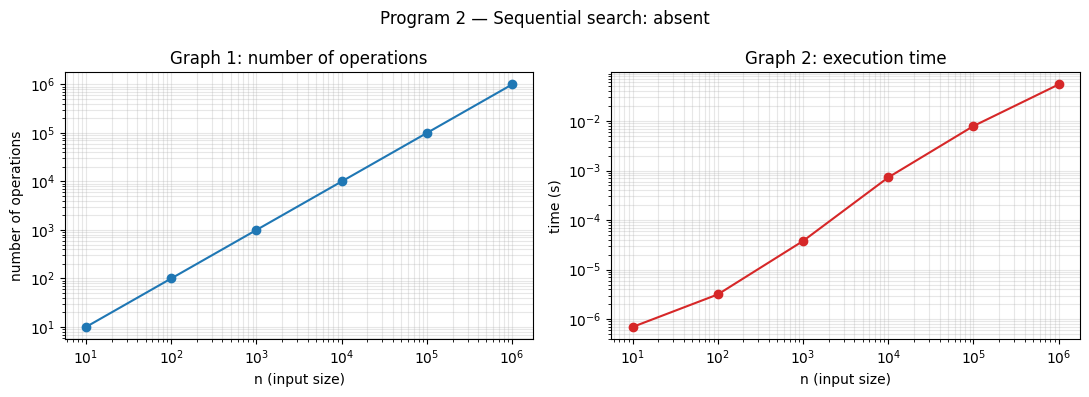

In [6]:
plot("Program 2 — Sequential search: start", sizes, ops_start, t_start)
plot("Program 2 — Sequential search: middle", sizes, ops_middle, t_middle)
plot("Program 2 — Sequential search: end", sizes, ops_end, t_end)
plot("Program 2 — Sequential search: absent", sizes, ops_absent, t_absent)

> ✍️ **What I observe as n grows:** start: always 1 operation, and the time stays almost constant. Middle, end and absent: the number of operations is multiplied by 10 when $n$ is multiplied by 10 (≈ n/2 for the middle, n for the end and absent). The time follows the same trend.
>
> ✍️ **Conclusion about the algorithm's behaviour:** sequential search depends heavily on the position of the element. In the worst case (end or absent), the work grows at the same rate as the size of the array.

---
# Program 3 — Two nested loops

```python
def two_loops(n):
    counter = 0
    for i in range(n):
        for j in range(n):
            counter += 1   # elementary operation
    return counter
```

**What does this program do?** It performs one operation for each pair $(i, j)$. There are two levels of repetition.

**Elementary operation to count:** `counter += 1`.

> ⏱️ This program gets slow quickly: we **double** $n$ at each measurement instead of multiplying it by 10.

In [7]:
def two_loops(n):
    counter = 0
    for i in range(n):
        for j in range(n):
            counter += 1   # elementary operation
    return counter

### ✍️ To program
Following the model of program 1: measurement loop, table, graphs.

         n |   operations (count) |   time (s)
-----------------------------------------------
        10 |                  100 |   0.000002
        20 |                  400 |   0.000009
        40 |                1,600 |   0.000039
        80 |                6,400 |   0.000160
       160 |               25,600 |   0.000627
       320 |              102,400 |   0.003397
       640 |              409,600 |   0.014246
     1,280 |            1,638,400 |   0.057182


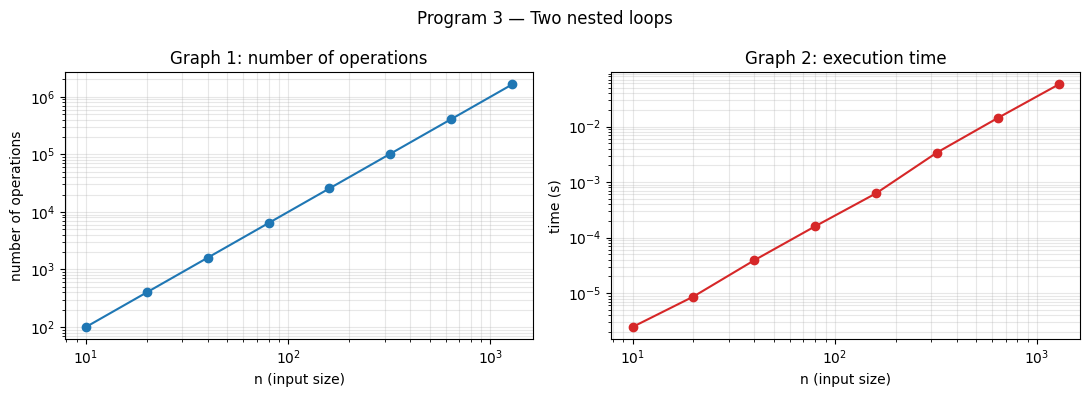

In [8]:
sizes = [10, 20, 40, 80, 160, 320, 640, 1_280]
operations, times = [], []

for n in sizes:
    operations.append(two_loops(n))
    times.append(timer(two_loops, n))

show_table(sizes, operations, times)
plot("Program 3 — Two nested loops", sizes, operations, times)

> ✍️ **What I observe as n grows:** when $n$ doubles, the number of operations is multiplied by 4 (100, 400, 1,600…) and so is the time (roughly). On the log-log scale, the lines rise twice as steeply as for program 1.
>
> ✍️ **Conclusion about the algorithm's behaviour:** the work grows very quickly with the input size: doubling $n$ multiplies the work by 4.

---
# Program 4 — Repeated division by 2

```python
def halvings(n):
    counter = 0
    while n > 1:
        n = n // 2
        counter += 1   # elementary operation
    return counter
```

**What does this program do?** It divides $n$ by 2 at each step as long as $n$ is greater than 1. The number of steps depends on $n$.

**Elementary operation to count:** `counter += 1`.

In [9]:
def halvings(n):
    counter = 0
    while n > 1:
        n = n // 2
        counter += 1   # elementary operation
    return counter

### ✍️ To program

         n |   operations (count) |   time (s)
-----------------------------------------------
        10 |                    3 |   0.000001
       100 |                    6 |   0.000000
     1,000 |                    9 |   0.000001
    10,000 |                   13 |   0.000001
   100,000 |                   16 |   0.000001
 1,000,000 |                   19 |   0.000001


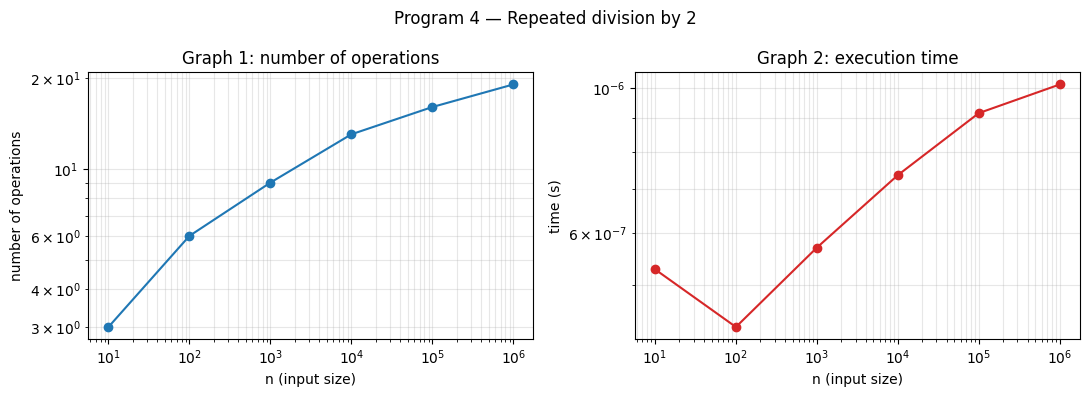

In [10]:
sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
operations, times = [], []

for n in sizes:
    operations.append(halvings(n))
    times.append(timer(halvings, n))

show_table(sizes, operations, times)
plot("Program 4 — Repeated division by 2", sizes, operations, times)

> ✍️ **What I observe as n grows:** the number of steps grows very slowly: only +3 or +4 when $n$ is multiplied by 10 (19 steps for one million). The time stays tiny. The curve is almost flat.
>
> ✍️ **Conclusion about the algorithm's behaviour:** the work grows very slowly with the input size; this algorithm is much faster than the previous ones for large values of $n$.

---
# Program 5 — Naive recursive Fibonacci

```python
def fibonacci(n):
    if n <= 1:
        return n
    return fibonacci(n - 1) + fibonacci(n - 2)
```

**What does this program do?** It computes the $n$-th Fibonacci number with a naive recursion. The number of calls grows very quickly as $n$ grows.

**Elementary operation to count:** each recursive call made (increment a counter at the **start** of the function).

> ⚠️ **Warning:** only test small values of $n$ (e.g. $n \le 35$).

### ✍️ To program
The program does not have a counter yet. Write `naive_fib(n, counter)`: it is the same program, with a **counter** passed as a parameter.

`counter` is a list `[0]` (a list can be modified inside the function): add `counter[0] += 1` at the **start** of the function, and pass `counter` to both recursive calls.

In [11]:
def naive_fib(n, counter):
    counter[0] += 1           # one function call
    if n <= 1:                # base case
        return n
    return naive_fib(n - 1, counter) + naive_fib(n - 2, counter)

counter = [0]
value = naive_fib(10, counter)
print("F(10) =", value, "| calls:", counter[0])     # expected: F(10) = 55 | calls: 177

F(10) = 55 | calls: 177


Then the measurement loop. For each $n$, create a **new** counter `[0]`. (You can add 32, 34, 35 at the end if you have time: $n = 35$ takes several seconds.)

         n |   operations (count) |   time (s)
-----------------------------------------------
         5 |                   15 |   0.000002
        10 |                  177 |   0.000015
        15 |                1,973 |   0.000171
        20 |               21,891 |   0.002037
        25 |              242,785 |   0.022672
        30 |            2,692,537 |   0.246699


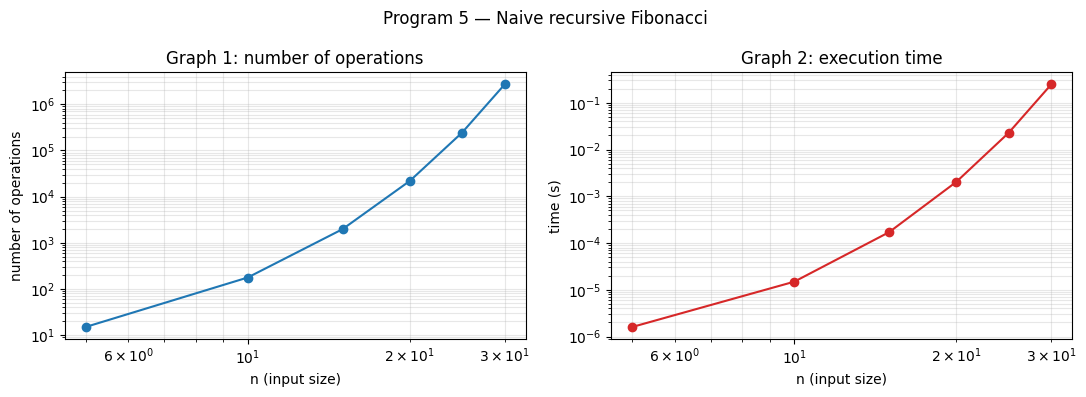

In [12]:
sizes = [5, 10, 15, 20, 25, 30]
operations, times = [], []

for n in sizes:
    counter = [0]
    naive_fib(n, counter)
    operations.append(counter[0])
    times.append(timer(naive_fib, n, [0]))

show_table(sizes, operations, times)
plot("Program 5 — Naive recursive Fibonacci", sizes, operations, times)

> ✍️ **What I observe as n grows:** the number of calls grows extremely fast: from $n$ to $n+1$ it is multiplied by about 1.6 (177 calls for $n = 10$, more than 2.6 million for $n = 30$). The time follows the same trend and becomes very large around $n = 35$.
>
> ✍️ **Conclusion about the algorithm's behaviour:** the work grows extremely fast with the input size: the algorithm becomes impractical for moderate values of $n$, because of the many calls that recompute the same values.

---
# Qualitative comparison

| Program | Observed growth (qualitative) |
|---|---|
| Simple traversal | grows steadily, at the same rate as $n$ |
| Sequential search | from constant (x at the start) to steady like $n$ (x at the end or absent) |
| Two nested loops | grows very fast (× 4 when $n$ doubles) |
| Repeated division by 2 | grows very slowly (+1 when $n$ doubles) |
| Naive recursive Fibonacci | grows extremely fast (much faster than the two loops) |

---
# 📤 What to submit

1. Put this notebook in `aac-tp/tp1_complexity/`.
2. Complete every "TO COMPLETE" cell and every ✍️ line.
3. Check that **every graph shows the program name**.
4. **Restart & Run All**: no errors.
5. Push it to GitHub:

```bash
git add tp1_complexity/
git commit -m "Lab 1: experimental discovery of complexity"
git push
```

### ➡️ Next session: **Lab 2 — Time Complexity Analysis** (Big O notation)